In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


ESG 바스켓 비용 VQE 후보: ['A'] 목적값: 0.330431
ESG 바스켓 비용 QAOA 후보: ['A'] 목적값: 0.330431


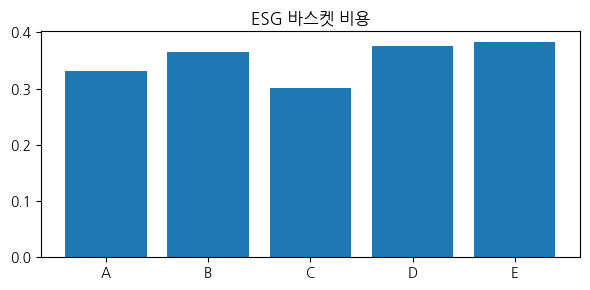

행 1: 정규화 지표=[0.444 0.342 0.444 0.455 0.429 0.484 0.556] | 위험=0.393 | 부담=0.550
행 2: 정규화 지표=[0.556 0.466 0.333 0.545 0.214 0.387 0.444] | 위험=0.400 | 부담=0.619
행 3: 정규화 지표=[0.889 0.726 0.667 0.318 0.571 0.161 0.333] | 위험=0.696 | 부담=0.612

기본 바스켓 비용: [0.3304 0.365  0.3008 0.3754 0.3826]
환경 비중 증가 비용: [0.3322 0.3645 0.2981 0.3722 0.3792]


In [3]:
import numpy as np
import torch
from torch import nn
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorEstimator, StatevectorSampler

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA as VCOBYLA
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer


# ==========================================================
# 1) 공통 함수 및 모듈 선언 (앞서 만든 기능들)
# ==========================================================
def minmax(v):
    return (v - v.min()) / max(float(np.ptp(v)), 1e-12)

def train_classifier(features, labels, title, split=None):
    torch.manual_seed(42)
    indices = np.arange(len(labels))
    train, test = (train_test_split(indices, test_size=0.3, stratify=labels, random_state=42)
                   if split is None else split)
    low, width = features[train].min(axis=0), np.ptp(features[train], axis=0)
    normalized = np.clip((features - low) / np.where(width > 0, width, 1), 0, 1)
    X = torch.tensor(0.05 + 0.9 * normalized, dtype=torch.float32)
    y = torch.tensor(labels[:, None], dtype=torch.float32)

    inputs, weights = ParameterVector('x', 2), ParameterVector('theta', 8)
    circuit = QuantumCircuit(2)
    for j in range(2): circuit.ry(np.pi * inputs[j], j)
    for layer in range(2):
        circuit.cx(layer % 2, 1 - layer % 2)
        for j in range(2):
            circuit.ry(weights[4 * layer + 2 * j], j)
            circuit.rz(weights[4 * layer + 2 * j + 1], j)

    observables = [SparsePauliOp.from_list([(name, 1)]) for name in ['ZI', 'IZ', 'ZZ']]
    qnn = EstimatorQNN(circuit=circuit, estimator=StatevectorEstimator(),
        observables=observables, input_params=list(inputs), weight_params=list(weights),
        default_precision=0.0, input_gradients=True)

    model = nn.Sequential(TorchConnector(qnn, initial_weights=np.linspace(-0.3, 0.3, 8)),
                          nn.Linear(3, 1))
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.03, weight_decay=0.01)
    loss_fn = nn.BCEWithLogitsLoss()

    for epoch in range(20):
        optimizer.zero_grad()
        logits = model(X[train]); loss = loss_fn(logits, y[train])
        loss.backward(); optimizer.step()

    with torch.no_grad():
        probabilities = torch.sigmoid(model(X))
    return probabilities.numpy().ravel()

def run_vqe(problem, title, seed=42):
    converter = QuadraticProgramToQubo()
    qubo = converter.convert(problem)
    H, offset = qubo.to_ising()
    n = qubo.get_num_vars()
    ansatz = real_amplitudes(n, reps=2, entanglement="linear")
    vqe = VQE(StatevectorEstimator(), ansatz, VCOBYLA(maxiter=40),
              initial_point=np.random.default_rng(seed).uniform(-1, 1, ansatz.num_parameters))
    result = vqe.compute_minimum_eigenvalue(H)
    state = Statevector.from_instruction(ansatz.assign_parameters(result.optimal_parameters))
    probabilities = state.probabilities()
    candidates = []
    for i, p in enumerate(probabilities):
        bits = np.array([(i >> j) & 1 for j in range(n)])
        x = np.asarray(converter.interpret(bits))
        if problem.is_feasible(x):
            candidates.append((float(p), x))
    probability, chosen = max(candidates, key=lambda item: item[0])
    return {"x": chosen, "fval": float(problem.objective.evaluate(chosen))}

def run_qaoa(problem, title, seed=42):
    qaoa = QAOA(StatevectorSampler(default_shots=1024, seed=seed),
                COBYLA(maxiter=30), reps=1,
                initial_point=np.random.default_rng(seed).uniform(0.1, 1, 2))
    result = MinimumEigenOptimizer(qaoa).solve(problem)
    return {"x": result.x, "fval": float(result.fval)}

def extension_problem(kind, data):
    v = np.column_stack([minmax(data[:, j]) for j in range(7)])
    if kind == 'ESG':
        risk = 0.5 * v[:, 1] + 0.5 * v[:, 2]
        friction = 0.4 * (1 - v[:, 3]) + 0.4 * (1 - v[:, 4]) + 0.2 * (1 - v[:, 5])
        cost = 0.5 * risk + 0.3 * friction - 0.2 * v[:, 0] + 0.1 * (1 - v[:, 6])
    else:
        risk = 0.4 * v[:, 1] + 0.4 * (1 - v[:, 3]) + 0.2 * v[:, 4]
        friction = 0.5 * (1 - v[:, 2]) + 0.5 * v[:, 5]
        cost = 0.5 * risk + 0.3 * friction - 0.2 * v[:, 0] + 0.1 * (1 - v[:, 6])

    train, test = train_test_split(np.arange(30), test_size=0.3, random_state=42)
    labels = (cost <= np.median(cost[train])).astype(float)
    probabilities = train_classifier(np.column_stack([risk, friction]), labels, kind + ' QNN', (train, test))

    basket_cost = cost.reshape(5, 6).mean(axis=1)
    problem = QuadraticProgram()
    for name in 'ABCDE': problem.binary_var(name)
    problem.minimize(linear=basket_cost)
    problem.linear_constraint({name: 1 for name in 'ABCDE'}, '==', 1, 'one_basket')

    qaoa_result = run_qaoa(problem, kind + ' QAOA')
    vqe_result = run_vqe(problem, kind + ' VQE')

    return {
        'risk': risk, 'friction': friction, 'cost': cost, 'basket_cost': basket_cost,
        'labels': labels, 'probabilities': probabilities, 'test': test,
        'qaoa_bits': qaoa_result["x"].copy(), 'vqe_bits': vqe_result["x"].copy()
    }

def compare_baskets(report, title):
    basket_names = np.array(list('ABCDE'))
    costs = report['basket_cost']
    exact_index = int(np.argmin(costs))
    for method, key in [('VQE', 'vqe_bits'), ('QAOA', 'qaoa_bits')]:
        bits = np.rint(report[key]).astype(int)
        if bits.sum() != 1:
            bits = np.zeros_like(bits); bits[exact_index] = 1
        selected_cost = float(costs @ bits)
        print(title, method, '후보:', basket_names[bits == 1].tolist(),
              '목적값:', round(selected_cost, 6))
    plt.figure(figsize=(6, 3)); plt.bar(basket_names, costs)
    plt.title(title); plt.tight_layout(); plt.show(); plt.close()


# ==========================================================
# 2) ESG 데이터 정의 및 시나리오 분석 실행부
# ==========================================================
esg_data = np.array([
 [0.7, 8.2, 120, 78, 82, 55, 0.3],
 [0.8, 9.1, 110, 80, 79, 52, 0.2],
 [1.1,11.0, 140, 75, 84, 45, 0.1],
 [0.6, 7.3, 100, 83, 81, 61, 0.4],
 [0.9,10.5, 160, 70, 78, 50, 0.0],
 [0.5, 6.8, 90, 86, 85, 65, 0.5],
 [1.0,11.7, 150, 74, 77, 48, -0.1],
 [0.4, 6.4, 85, 88, 88, 68, 0.6],
 [1.2,12.5, 170, 69, 80, 43, -0.2],
 [0.3, 5.9, 82, 89, 89, 70, 0.7],
 [0.8, 9.5, 130, 76, 83, 54, 0.3],
 [1.0,11.3, 145, 73, 80, 49, 0.0],
 [0.5, 7.0, 95, 85, 86, 63, 0.5],
 [0.9,10.9, 150, 72, 79, 47, 0.1],
 [0.4, 6.5, 88, 87, 87, 66, 0.6],
 [1.1,12.1, 155, 71, 78, 46, -0.1],
 [0.6, 7.6, 98, 84, 84, 60, 0.4],
 [0.7, 8.4,105, 82, 83, 57, 0.3],
 [1.2,12.9,165, 68, 76, 41, -0.2],
 [0.3, 5.7, 80, 90, 90, 71, 0.7],
 [1.0,11.6,150, 73, 81, 44, 0.1],
 [0.5, 7.2, 92, 86, 85, 62, 0.5],
 [0.8, 9.7,128, 77, 82, 53, 0.2],
 [0.9,10.8,140, 74, 79, 50, 0.0],
 [0.4, 6.6, 86, 88, 87, 67, 0.6],
 [1.1,12.2,158, 70, 77, 42, -0.1],
 [0.5, 6.9, 94, 84, 83, 59, 0.4],
 [1.2,13.0,165, 68, 76, 40, -0.2],
 [0.6, 7.8,102, 81, 82, 58, 0.3],
 [0.9,10.5,138, 75, 80, 52, 0.1],
], dtype=np.float32)

# 파이프라인 실행 및 검증
esg_report = extension_problem('ESG', esg_data)
compare_baskets(esg_report, 'ESG 바스켓 비용')

# 시나리오 분석 (환경 리스크 가중치 변경 실험)
normalized_esg = np.column_stack([minmax(esg_data[:, j]) for j in range(7)])
for row in range(3):
    print(f'행 {row+1}: 정규화 지표={normalized_esg[row].round(3)} | '
          f'위험={float(esg_report["risk"][row]):.3f} | 부담={float(esg_report["friction"][row]):.3f}')

new_risk = 0.3 * normalized_esg[:, 1] + 0.7 * normalized_esg[:, 2]
changed_cost = (0.5 * new_risk + 0.3 * esg_report['friction'] - 0.2 * normalized_esg[:, 0] + 0.1 * (1 - normalized_esg[:, 6]))

print('\n기본 바스켓 비용:', esg_report['basket_cost'].round(4))
print('환경 비중 증가 비용:', changed_cost.reshape(5, 6).mean(axis=1).round(4))